# 1. Open datasets

In [1]:
%pip install -r ../requirements.txt

  Using cached numpy-1.26.4-cp312-cp312-macosx_11_0_arm64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-macosx_11_0_arm64.whl (13.7 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from pathlib import Path
import sys

# Works when running from the project root or notebooks/
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.preprocessing import canonicalize_smiles

In [3]:

from tdc.single_pred import ADME, Tox
import pandas as pd

# Save datasets in the project-level data directory
raw_dir = project_root / "data"
raw_dir.mkdir(parents=True, exist_ok=True)

# Load regression dataset
solubility = ADME(name="Solubility_AqSolDB", path=str(raw_dir))
df_reg = solubility.get_data()
df_reg.to_csv(raw_dir / "solubility_aqsoldb.tab", sep="\t", index=False)

# Load classification dataset
herg = Tox(name="hERG", path=str(raw_dir))
df_clf = herg.get_data()
df_clf.to_csv(raw_dir / "herg.tab", sep="\t", index=False)

# Preview datasets and report shapes
display(df_reg.head(10))
display(df_clf.head(10))
print("Regression:", df_reg.shape)
print("Classification:", df_clf.shape)

Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!


,Drug_ID,Drug,Y
0,"N,N,N-trimethyloctadecan-1-aminium bromide",CCCCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-],-3.616127
1,Benzo[cd]indol-2(1H)-one,O=C1Nc2cccc3cccc1c23,-3.254767
2,4-chlorobenzaldehyde,O=Cc1ccc(Cl)cc1,-2.177078
3,"zinc bis[2-hydroxy-3,5-bis(1-phenylethyl)benzo...",CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...,-3.924409
4,4-({4-[bis(oxiran-2-ylmethyl)amino]phenyl}meth...,c1cc(N(CC2CO2)CC2CO2)ccc1Cc1ccc(N(CC2CO2)CC2CO...,-4.662065
5,vinyltoluene,C=Cc1cccc(C)c1,-3.123150
6,3-(3-ethylcyclopentyl)propanoic acid,CCC1CCC(CCC(=O)O)C1,-3.286116
7,"11,16,17,21-tetrahydroxypregna-1,4-diene-3,20-...",CC12C=CC(=O)C=C1CCC1C2C(O)CC2(C)C1CC(O)C2(O)C(...,-2.664549
8,bis(4-fluorophenyl)methanone,O=C(c1ccc(F)cc1)c1ccc(F)cc1,-4.396652
9,1-[2-(benzoyloxy)propoxy]propan-2-yl benzoate ...,O=C(OCCCOCCCOC(=O)c1ccccc1)c1ccccc1,-4.595503


,Drug_ID,Drug,Y
0,DEMETHYLASTEMIZOLE,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1,1.0
1,GBR-12909,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...,1.0
2,LY-97241,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1,1.0
3,CLOFILIUM PHOSPHATE,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...,1.0
4,FLUSPIRILENE,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...,1.0
5,BENPERIDOL,O=C(CCCN1CCC(n2c(=O)[nH]c3ccccc32)CC1)c1ccc(F)cc1,1.0
6,NaN,Fc1ccc(-n2cc(C3CCN(CCN4CCNC4=S)CC3)c3ccccc32)cc1,1.0
7,BMCL20031829_03,O=C1NCCN1CCN1CCC(c2cn(-c3ccc(F)cc3)c3ccccc23)CC1,1.0
8,VANOXERINE HYDROCHLORIDE,Fc1ccc(C(OCCN2CCN(CCCc3ccccc3)CC2)c2ccc(F)cc2)cc1,1.0
9,L-691121,CS(=O)(=O)Nc1ccc2c(c1)C(=O)CC1(CCN(CCc3ccc4non...,1.0


Regression: (9982, 3)
Classification: (655, 3)


# 2. Check for missing or invalid values

In [4]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import MolFromSmiles

In [5]:
#Solubility dataset

df_reg = solubility.get_data()

df_reg = df_reg.rename(columns={
    "Drug": "SMILES",
    "Y": "Solubility"
})

print("Dataset: Solubility_AqSolDB")
print("Target: Aqueous solubility")
print("Original rows:", len(df_reg))


print("Missing SMILES:", df_reg["SMILES"].isna().sum())
print("Missing solubility:", df_reg["Solubility"].isna().sum())

print(df_reg.columns)
display (df_reg.head(5))



Dataset: Solubility_AqSolDB
Target: Aqueous solubility
Original rows: 9982
Missing SMILES: 0
Missing solubility: 0
Index(['Drug_ID', 'SMILES', 'Solubility'], dtype='object')


,Drug_ID,SMILES,Solubility
0,"N,N,N-trimethyloctadecan-1-aminium bromide",CCCCCCCCCCCCCCCCCC[N+](C)(C)C.[Br-],-3.616127
1,Benzo[cd]indol-2(1H)-one,O=C1Nc2cccc3cccc1c23,-3.254767
2,4-chlorobenzaldehyde,O=Cc1ccc(Cl)cc1,-2.177078
3,"zinc bis[2-hydroxy-3,5-bis(1-phenylethyl)benzo...",CC(c1ccccc1)c1cc(C(=O)[O-])c(O)c(C(C)c2ccccc2)...,-3.924409
4,4-({4-[bis(oxiran-2-ylmethyl)amino]phenyl}meth...,c1cc(N(CC2CO2)CC2CO2)ccc1Cc1ccc(N(CC2CO2)CC2CO...,-4.662065


In [6]:
#hERG dataset

df_clf = herg.get_data()

df_clf = df_clf.rename(columns={
    "Drug": "SMILES",
    "Y": "Blocking_status"
})

print("Dataset: hERG")
print("Target: Blocking status") #if the molecule is either blocking or not
print("Original rows:", len(df_clf))


print("Missing SMILES:", df_clf["SMILES"].isna().sum())
print("Missing hERG:", df_clf["Blocking_status"].isna().sum())

display (df_clf.head(5))

Dataset: hERG
Target: Blocking status
Original rows: 655
Missing SMILES: 0
Missing hERG: 0


,Drug_ID,SMILES,Blocking_status
0,DEMETHYLASTEMIZOLE,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1,1.0
1,GBR-12909,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...,1.0
2,LY-97241,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1,1.0
3,CLOFILIUM PHOSPHATE,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...,1.0
4,FLUSPIRILENE,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...,1.0


# 3. Solubility dataset analysis

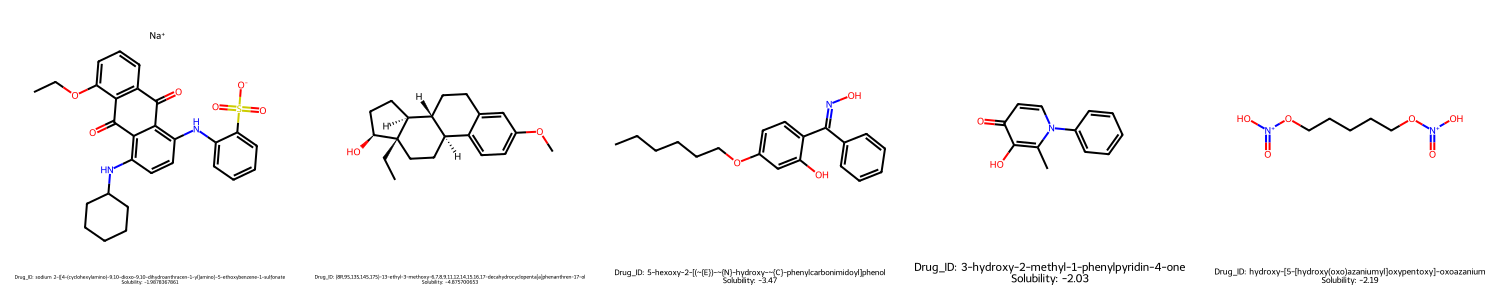

In [7]:
# Visualization of some molecules from the dataset
n = 5
df_sample = df_reg.sample(n)

smiles = df_sample["SMILES"].values
legends = [
    f"Drug_ID: {drug_id}\nSolubility: {solubility_value}"
    for drug_id, solubility_value in zip(
        df_sample["Drug_ID"], df_sample["Solubility"]
    )
]
molecs = [Chem.MolFromSmiles(smile) for smile in smiles]

display(Draw.MolsToGridImage(
    molecs,
    molsPerRow=5,
    subImgSize=(300, 300),
    legends=legends
))

In [8]:
# Convert solubility values to numbers
numeric_target = pd.to_numeric(df_reg["Solubility"], errors="coerce")

# Identify NaN, infinite values and failed conversions
invalid_target = ~np.isfinite(numeric_target)

print("Invalid solubility values:", invalid_target.sum())

if invalid_target.any():
    display(df_reg.loc[invalid_target])
    raise ValueError("Invalid solubility values to inspect.")

# Keep the numeric values if all checks pass
df_reg["Solubility"] = numeric_target

print("All solubility targets are valid.")

Invalid solubility values: 0
All solubility targets are valid.


In [9]:
#canonicalization
df_reg["Canonical_smiles"] = df_reg["SMILES"].apply(canonicalize_smiles)

# Count invalid structures before removing them
print("Invalid SMILES — solubility:",
      df_reg["Canonical_smiles"].isna().sum())

# Keep only valid structures
df_reg = df_reg.dropna(subset=["Canonical_smiles"]).copy()
print("Remaining rows — solubility:", len(df_reg))


[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not removing hydrogen atom without neighbors
[18:25:29] WARNING: not r

Invalid SMILES — solubility: 0
Remaining rows — solubility: 9982


In [10]:
# Identify SMILES containing multiple disconnected fragments.
# These fragments are separated by a literal "." in the SMILES
# and may represent salts or mixtures.
# regex=False ensures that "." is treated as a literal character.
n_multifragment = df_reg["Canonical_smiles"].str.contains(
    ".", regex=False, na=False
).sum()

print("Rows with multiple fragments:", n_multifragment)

Rows with multiple fragments: 1098


In [13]:
# Identify all rows sharing the same canonical SMILES.

dup = df_reg.duplicated(subset="Canonical_smiles", keep=False)
print("Rows involved in duplicates:", dup.sum())
print(
    "Distinct duplicated structures:",
    df_reg.loc[dup, "Canonical_smiles"].nunique()
)

Rows involved in duplicates: 0
Distinct duplicated structures: 0


count    9982.000000
mean       -2.889909
std         2.368154
min       -13.171900
25%        -4.326325
50%        -2.618173
75%        -1.209735
max         2.137682
Name: Solubility, dtype: float64


Text(0, 0.5, 'Number of molecules')

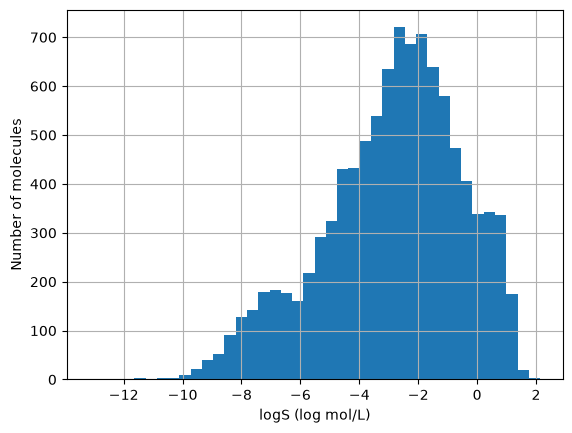

In [14]:
# Summarize solubility values and visualize how frequently they occur.



print(df_reg["Solubility"].describe())
df_reg["Solubility"].hist(bins=40)
plt.xlabel("logS (log mol/L)")
plt.ylabel("Number of molecules")

The histogram shows the distribution of aqueous solubility, expressed as logS in mol/L. Most compounds have negative logS values; the median is about -2.62, corresponding to roughly 2.4 mmol/L. The long tail toward very low values indicates that some compounds are much less soluble than the majority.

### Solubility dataset: summary and conclusion

The AqSolDB dataset contains **9,982 compounds**. No missing SMILES or solubility values were found, and all solubility targets and SMILES passed the validation checks. After canonicalizing the structures, no duplicate structures were detected.

The target is aqueous solubility expressed as **logS (mol/L)**. Values range from **−13.17 to 2.14**, with a mean of **−2.89** and a median of **−2.62**. The mostly negative values indicate that many compounds have limited aqueous solubility. The lower mean and the broad range suggest that the distribution includes some compounds with particularly low solubility.

A total of **1,098 structures contain multiple disconnected fragments**. These may represent salts or other multi-fragment entries; they are not necessarily invalid, but should be considered when interpreting molecular features and preparing the data for modeling.

**Conclusion:** The dataset has valid targets and structures, and its canonical structures are unique, so it is suitable for regression analysis after preprocessing.

# 2.1 Saving the cleaned datasets

In [15]:
df_reg.to_csv(raw_dir / "solubility_clean.csv", index=False)

# 3. hERG dataset analysis

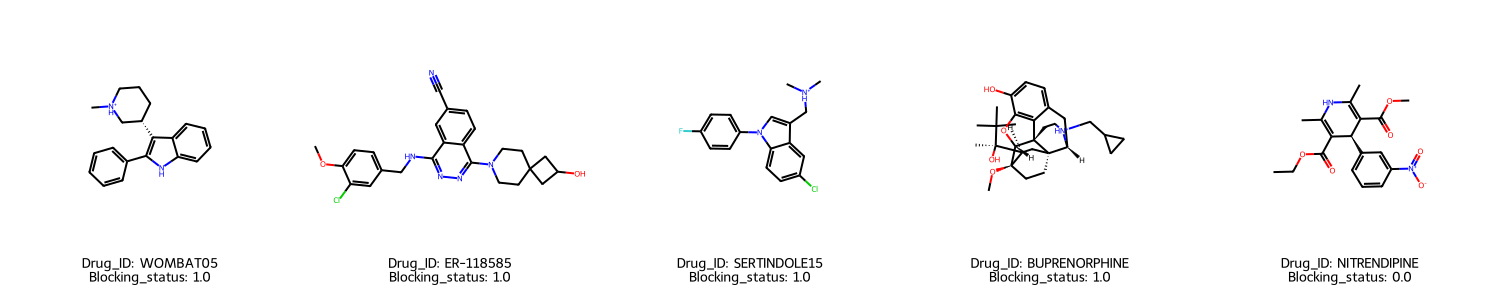

In [16]:
# Visualization of some molecules from the dataset
n = 5
df_sample= df_clf.sample(n)

smiles = df_sample["SMILES"].values
legends = [
    f"Drug_ID: {drug_id}\nBlocking_status: {hERG_blocking}"
    for drug_id, hERG_blocking in zip(
        df_sample["Drug_ID"], df_sample["Blocking_status"]
    )
]
molecs = [Chem.MolFromSmiles(smile) for smile in smiles]

display(Draw.MolsToGridImage(
    molecs,
    molsPerRow=5,
    subImgSize=(300, 300),
    legends=legends))

In [17]:
# Set the column names
smiles_col = 'SMILES'
target_col = 'Blocking_status'  

# Check the target values
print("Target distribution:")
print(df_clf[target_col].value_counts(dropna=False))

# Count missing targets and SMILES
print("Missing targets:", df_clf[target_col].isna().sum())

# Remove rows with missing targets
df_clf = df_clf.dropna(subset=[target_col]).copy()

print("Rows after removing missing targets:", len(df_clf))

Target distribution:
Blocking_status
1.0    451
0.0    204
Name: count, dtype: int64
Missing targets: 0
Rows after removing missing targets: 655


In [18]:
#Create a molecule column and check invalid SMILES

# Convert SMILES into molecule objects
df_clf['Molecule'] = df_clf[smiles_col].apply(
    lambda x: Chem.MolFromSmiles(x) if isinstance(x, str) else None)

# Count invalid SMILES
invalid_smiles = df_clf['Molecule'].isna().sum()
print("Invalid SMILES:", invalid_smiles)

# Remove invalid SMILES
df_clf = df_clf.dropna(subset=['Molecule']).copy()

print("Rows after removing invalid SMILES:", len(df_clf))

Invalid SMILES: 0
Rows after removing invalid SMILES: 655


[18:26:38] WARNING: not removing hydrogen atom without neighbors
[18:26:38] WARNING: not removing hydrogen atom without neighbors


In [19]:
# Apply the canonicaluzation function to the dataset
df_clf["Canonical_smiles"] = df_clf["SMILES"].apply(canonicalize_smiles)

df_clf.head()

[18:26:38] WARNING: not removing hydrogen atom without neighbors
[18:26:38] WARNING: not removing hydrogen atom without neighbors


,Drug_ID,SMILES,Blocking_status,Molecule,Canonical_smiles
0,DEMETHYLASTEMIZOLE,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1,1.0,<rdkit.Chem.rdchem.Mol object at 0x307d35d20>,Oc1ccc(CCN2CCC(Nc3nc4ccccc4n3Cc3ccc(F)cc3)CC2)cc1
1,GBR-12909,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...,1.0,<rdkit.Chem.rdchem.Mol object at 0x3112da570>,Fc1ccc(C(OCC[NH+]2CC[NH+](CCCc3ccccc3)CC2)c2cc...
2,LY-97241,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1,1.0,<rdkit.Chem.rdchem.Mol object at 0x3112d9460>,CCCCCCCN(CC)CCCCc1ccc([N+](=O)[O-])cc1
3,CLOFILIUM PHOSPHATE,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...,1.0,<rdkit.Chem.rdchem.Mol object at 0x3112d9310>,CCCCCCC[N+](CC)(CC)CCCCc1ccc(Cl)cc1.CCCCCCC[N+...
4,FLUSPIRILENE,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...,1.0,<rdkit.Chem.rdchem.Mol object at 0x3112d9380>,O=C1NCN(c2ccccc2)C12CC[NH+](CCCC(c1ccc(F)cc1)c...


In [20]:
# Convert target values to numbers and check that they are binary.
numeric_target = pd.to_numeric(df_clf[target_col], errors="coerce")
invalid_target = ~numeric_target.isin([0, 1])

print("Invalid target values:", invalid_target.sum())

if invalid_target.any():
    display(df_clf.loc[invalid_target])
    raise ValueError("Unexpected target values to inspect.")

df_clf[target_col] = numeric_target.astype(int)

# Check whether canonicalization failed for any structure.
print("Missing canonical SMILES:", df_clf["Canonical_smiles"].isna().sum())

Invalid target values: 0
Missing canonical SMILES: 0


In [21]:
#Identify duplicates and conflicting targets

# Count duplicate structures
print("Duplicate structures:", df_clf['Canonical_smiles'].duplicated().sum())

# Find structures with different target values
target_counts = df_clf.groupby('Canonical_smiles')[target_col].nunique()

conflicting_smiles = target_counts[target_counts > 1].index

print("Structures with conflicting targets:", len(conflicting_smiles))

Duplicate structures: 7
Structures with conflicting targets: 3


In [22]:
# Display all rows sharing the same canonical structure.
duplicate_mask = df_clf.duplicated(
    subset="Canonical_smiles",
    keep=False #each line of a duplicated canonical smile is marked true
) 

print("Rows sharing the same canonical structure:")
display(
    df_clf.loc[duplicate_mask]
    .sort_values("Canonical_smiles")
)

print("Conflicting target labels:")
# Display structures associated with conflicting target labels.
display(
    df_clf.loc[
        df_clf["Canonical_smiles"].isin(conflicting_smiles)
    ].sort_values("Canonical_smiles")
)

Rows sharing the same canonical structure:


,Drug_ID,SMILES,Blocking_status,Molecule,Canonical_smiles
183,BMCL20031829_19,CCC(=O)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12,1,<rdkit.Chem.rdchem.Mol object at 0x3118d2960>,CCC(=O)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12
514,SERTINDOLE19,CCC(=O)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12,0,<rdkit.Chem.rdchem.Mol object at 0x3118cbae0>,CCC(=O)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12
167,BMCL20031829_17,CCC(CC)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12,1,<rdkit.Chem.rdchem.Mol object at 0x3118d2260>,CCC(CC)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12
512,SERTINDOLE17,CCC(CC)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12,0,<rdkit.Chem.rdchem.Mol object at 0x3118cba00>,CCC(CC)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12
83,MEPERIDINE,CCOC(=O)C1(c2ccccc2)CCN(C)CC1,1,<rdkit.Chem.rdchem.Mol object at 0x3112dbd10>,CCOC(=O)C1(c2ccccc2)CCN(C)CC1
440,PETHIDINE HYDROCHLORIDE,CCOC(=O)C1(c2ccccc2)CCN(C)CC1,1,<rdkit.Chem.rdchem.Mol object at 0x3118c9a80>,CCOC(=O)C1(c2ccccc2)CCN(C)CC1
224,BMCL20031829_22,CCc1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12,1,<rdkit.Chem.rdchem.Mol object at 0x3118d3b50>,CCc1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12
519,SERTINDOLE22,CCc1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12,0,<rdkit.Chem.rdchem.Mol object at 0x3118cbd10>,CCc1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12
135,BISINDOLYLMALEIMIDE-I,CN(C)CCCn1cc(C2=C(c3c[nH]c4ccccc34)C(=O)NC2=O)...,1,<rdkit.Chem.rdchem.Mol object at 0x3118d1460>,CN(C)CCCn1cc(C2=C(c3c[nH]c4ccccc34)C(=O)NC2=O)...
137,GF-109203X,CN(C)CCCn1cc(C2=C(c3c[nH]c4ccccc34)C(=O)NC2=O)...,1,<rdkit.Chem.rdchem.Mol object at 0x3118d1540>,CN(C)CCCn1cc(C2=C(c3c[nH]c4ccccc34)C(=O)NC2=O)...


Conflicting target labels:


,Drug_ID,SMILES,Blocking_status,Molecule,Canonical_smiles
183,BMCL20031829_19,CCC(=O)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12,1,<rdkit.Chem.rdchem.Mol object at 0x3118d2960>,CCC(=O)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12
514,SERTINDOLE19,CCC(=O)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12,0,<rdkit.Chem.rdchem.Mol object at 0x3118cbae0>,CCC(=O)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12
167,BMCL20031829_17,CCC(CC)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12,1,<rdkit.Chem.rdchem.Mol object at 0x3118d2260>,CCC(CC)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12
512,SERTINDOLE17,CCC(CC)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12,0,<rdkit.Chem.rdchem.Mol object at 0x3118cba00>,CCC(CC)c1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12
224,BMCL20031829_22,CCc1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12,1,<rdkit.Chem.rdchem.Mol object at 0x3118d3b50>,CCc1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12
519,SERTINDOLE22,CCc1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12,0,<rdkit.Chem.rdchem.Mol object at 0x3118cbd10>,CCc1cn(-c2ccc(F)cc2)c2ccc(Cl)cc12


In [23]:
# Remove all rows for structures with conflicting target labels.
conflict_mask = df_clf["Canonical_smiles"].isin(conflicting_smiles)

print("Conflicting structures removed:", len(conflicting_smiles))
print("Rows removed due to conflicting labels:", conflict_mask.sum())

df_clf = df_clf.loc[~conflict_mask].copy()

# Keep one occurrence of each remaining structure (labels now agree).
n_before = len(df_clf)

df_clf = df_clf.drop_duplicates(
    subset="Canonical_smiles",
    keep="first"
).reset_index(drop=True)

print("Additional duplicate rows removed:", n_before - len(df_clf))
print("Remaining molecules:", len(df_clf))


Conflicting structures removed: 3
Rows removed due to conflicting labels: 6
Additional duplicate rows removed: 4
Remaining molecules: 645


In [24]:
# Count remaining duplicates based on canonical SMILES.
n_duplicates = df_clf.duplicated(subset="Canonical_smiles").sum()

print("Remaining duplicate structures:", n_duplicates)


Remaining duplicate structures: 0


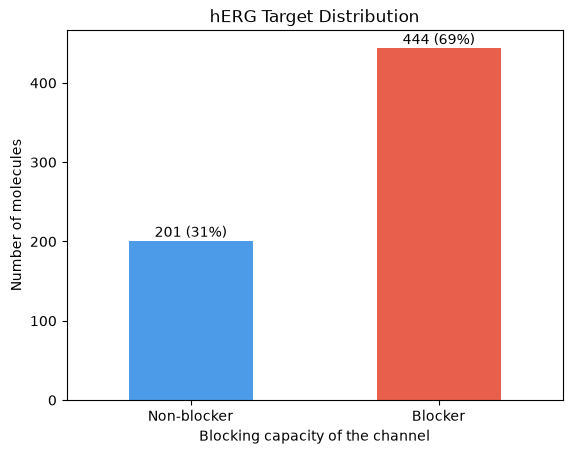

In [25]:
#Plot the target distribution
import matplotlib.pyplot as plt

palette = {0.0: '#4C9BE8', 1.0: '#E8604C'}

counts = df_clf[target_col].value_counts().sort_index()
ax = counts.plot(kind='bar', color=[palette[0.0], palette[1.0]])

# Show count and percentage above each bar
for i, v in enumerate(counts):
    ax.text(i, v + 5, f'{v} ({v/counts.sum():.0%})', ha='center')

plt.xticks([0, 1], ['Non-blocker', 'Blocker'], rotation=0)
plt.xlabel('Blocking capacity of the channel')
plt.ylabel('Number of molecules')
plt.title('hERG Target Distribution')
plt.show()


### Handling duplicate structures and conflicting labels

We identified 14 rows corresponding to 7 duplicated canonical structures.

Three structures had conflicting labels: each appeared once as a blocker
(1) and once as a non-blocker (0). Without additional experimental
information, we could not reliably determine which label was correct.
We therefore excluded all 6 rows associated with these structures.

The other 4 duplicated structures had consistent labels. We retained
one occurrence per structure, removing 4 additional rows to avoid
overrepresenting these molecules.

Overall, this cleaning removed 10 rows. 
Excluding conflicting structures
discards potentially useful information, but avoids choosing labels
arbitrarily.

# Save Cleaned dataset

In [26]:
# Save the cleaned dataset without RDKit molecule objects.
processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)



df_clf.drop(columns=["Molecule"], errors="ignore").to_csv(
    processed_dir / "herg_clean.csv",
    index=False
)

df_reg.drop(columns=["Molecule"], errors="ignore").to_csv (
    processed_dir/ 'solubility_clean.csv',
    index=False
)